# 00. Auditoria Pós-Atualização dos Dados



## IPCA • SELIC • PostgreSQL • IBGE/SIDRA • BCB/SGS

Este notebook é o ponto de entrada das análises do projeto. 

Ele deve ser executado **depois da atualização dos pipelines e das views**:

```bash
make run-all
make run-views
```

Seu objetivo é validar se os dados armazenados no PostgreSQL estão
suficientemente íntegros, atuais e consistentes para serem utilizados
pelos notebooks analíticos e, posteriormente, pelos modelos.

---


### Este notebook valida

1. Conexão com PostgreSQL
2. Existência do schema `bcb`
3. Existência das tabelas esperadas
4. Existência das views esperadas
5. Estrutura das tabelas
6. Quantidade e cobertura temporal
7. Valores nulos
8. Duplicidades
9. Continuidade mensal do IPCA
10. Hierarquia do IPCA
11. Pesos dos grupos
12. Faixas básicas de plausibilidade
13. Consistência entre componentes e IPCA geral
14. Integridade da SELIC
15. Funcionamento das views
16. Status final para início das análises

---



### Importante

Este notebook é **somente leitura**.

Ele NÃO:

- executa pipelines;
- faz `TRUNCATE`;
- insere dados;
- executa migrations;
- recria tabelas;
- recria views;
- corrige observações.

Se uma validação falhar, a causa deve ser corrigida no pipeline,
banco ou migration correspondente.

### 1. Configuração do ambiente

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /home/moacir/projects/ml/analytics/inflation


### 2. Importações

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import inspect, text

from src.database.connection import engine

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:.4f}".format)

### 3. Configuração da auditoria

Centralizamos aqui as estruturas que o projeto espera encontrar.

Se futuramente uma tabela ou view for adicionada ou removida de forma
intencional, este é um dos pontos que deverá ser atualizado.

In [3]:
SCHEMA = "bcb"

TABELAS_ESPERADAS = {
    "calendar",
    "ipca_geral",
    "ipca_grupos",
    "ipca_subgrupos",
    "ipca_itens",
    "ipca_subitens",
    "selic_meta",
    "selic_over",
}

VIEWS_ESPERADAS = {
    "vw_blocos_macro",
    "vw_ipca_grupos_por_subitens",
}

TABELAS_IPCA = [
    "ipca_geral",
    "ipca_grupos",
    "ipca_subgrupos",
    "ipca_itens",
    "ipca_subitens",
]

TABELAS_COMPONENTES = [
    "ipca_grupos",
    "ipca_subgrupos",
    "ipca_itens",
    "ipca_subitens",
]

TABELAS_SELIC = [
    "selic_meta",
    "selic_over",
]

### 4. Registro das validações

Além dos `asserts`, manteremos uma tabela de resultados para oferecer
uma visão consolidada no final do notebook.

In [4]:
resultados = []


def registrar_check(categoria, teste, ok=None, detalhe="", status=None):
    if status is None:
        status = "OK" if ok else "FALHA"

    resultados.append(
        {
            "categoria": categoria,
            "teste": teste,
            "status": status,
            "detalhe": detalhe,
        }
    )

---

## PARTE I — POSTGRESQL



### 5. Validar conexão

In [5]:
with engine.connect() as conn:
    db_info = conn.execute(
        text(
            """
            SELECT
                current_database() AS database,
                current_user AS usuario,
                current_schema() AS schema,
                version() AS versao;
            """
        )
    ).mappings().one()

db_info

{'database': 'bcb', 'usuario': 'moacir', 'schema': 'public', 'versao': 'PostgreSQL 16.15 (Ubuntu 16.15-0ubuntu0.24.04.1) on x86_64-pc-linux-gnu, compiled by gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0, 64-bit'}

In [6]:
registrar_check(
    "PostgreSQL",
    "Conexão com o banco",
    True,
    f"database={db_info['database']} | usuario={db_info['usuario']}",
)

print("Conexão PostgreSQL: OK")

Conexão PostgreSQL: OK


### 6. Verificar schema `bcb`

In [7]:
inspector = inspect(engine)

schemas = inspector.get_schema_names()

SCHEMA in schemas

True

In [8]:
schema_ok = SCHEMA in schemas

registrar_check(
    "PostgreSQL",
    "Schema bcb",
    schema_ok,
)

assert schema_ok, "Schema bcb não encontrado."

print("Schema bcb: OK")

Schema bcb: OK


### 7. Verificar tabelas

In [9]:
tabelas_existentes = set(
    inspector.get_table_names(schema=SCHEMA)
)

sorted(tabelas_existentes)

['calendar',
 'ipca_geral',
 'ipca_grupos',
 'ipca_itens',
 'ipca_subgrupos',
 'ipca_subitens',
 'selic_meta',
 'selic_over']

In [10]:
tabelas_faltantes = TABELAS_ESPERADAS - tabelas_existentes

registrar_check(
    "PostgreSQL",
    "Tabelas esperadas",
    not tabelas_faltantes,
    (
        "Todas encontradas"
        if not tabelas_faltantes
        else f"Faltando: {sorted(tabelas_faltantes)}"
    ),
)

assert not tabelas_faltantes, (
    f"Tabelas ausentes no schema bcb: "
    f"{sorted(tabelas_faltantes)}"
)

print("Tabelas esperadas: OK")

Tabelas esperadas: OK


### 8. Verificar views

In [11]:
views_existentes = set(
    inspector.get_view_names(schema=SCHEMA)
)

sorted(views_existentes)

['vw_blocos_macro', 'vw_ipca_grupos_por_subitens']

In [12]:
views_faltantes = VIEWS_ESPERADAS - views_existentes

registrar_check(
    "PostgreSQL",
    "Views esperadas",
    not views_faltantes,
    (
        "Todas encontradas"
        if not views_faltantes
        else f"Faltando: {sorted(views_faltantes)}"
    ),
)

assert not views_faltantes, (
    f"Views ausentes no schema bcb: "
    f"{sorted(views_faltantes)}"
)

print("Views esperadas: OK")

Views esperadas: OK


---

## PARTE II — SCHEMA DAS TABELAS



### 9. Inspecionar estrutura real

Esta etapa é particularmente importante porque o projeto passou por
alterações de nomenclatura e estrutura.

Não queremos descobrir durante a modelagem que o banco ainda utiliza
um schema antigo.

In [13]:
estrutura = []

for tabela in sorted(TABELAS_ESPERADAS):
    columns = inspector.get_columns(
        tabela,
        schema=SCHEMA,
    )

    for col in columns:
        estrutura.append(
            {
                "tabela": tabela,
                "coluna": col["name"],
                "tipo": str(col["type"]),
                "nullable": col["nullable"],
            }
        )

df_estrutura = pd.DataFrame(estrutura)

df_estrutura.head(15)

,tabela,coluna,tipo,nullable
0,calendar,date,DATE,True
1,calendar,year,INTEGER,True
2,calendar,month,INTEGER,True
3,calendar,month_name,TEXT,True
4,calendar,month_short,TEXT,True
5,calendar,day,INTEGER,True
6,calendar,day_of_year,INTEGER,True
7,calendar,week_number,INTEGER,True
8,calendar,quarter,INTEGER,True
9,calendar,quarter_name,TEXT,True


#### 9.1 Contratos mínimos esperados

In [14]:
CONTRATOS = {
    "ipca_geral": {
        "date",
        "indice",
        "acumulado",
        "acumulado12m",
    },
    "ipca_grupos": {
        "date",
        "indice",
        "peso",
        "categoria",
        "categoria_nome",
    },
    "ipca_subgrupos": {
        "date",
        "indice",
        "peso",
        "categoria",
        "categoria_nome",
    },
    "ipca_itens": {
        "date",
        "indice",
        "peso",
        "categoria",
        "categoria_nome",
    },
    "ipca_subitens": {
        "date",
        "indice",
        "peso",
        "categoria",
        "categoria_nome",
    },
    "selic_meta": {
        "date",
        "value",
    },
    "selic_over": {
        "date",
        "value",
    },
}

In [15]:
for tabela, esperadas in CONTRATOS.items():
    existentes = set(
        df_estrutura.loc[
            df_estrutura["tabela"] == tabela,
            "coluna",
        ]
    )

    faltantes = esperadas - existentes

    registrar_check(
        "Schema",
        tabela,
        not faltantes,
        (
            "Contrato OK"
            if not faltantes
            else f"Colunas faltando: {sorted(faltantes)}"
        ),
    )

    assert not faltantes, (
        f"{tabela}: colunas esperadas ausentes: "
        f"{sorted(faltantes)}"
    )

print("Contratos mínimos das tabelas: OK")

Contratos mínimos das tabelas: OK


---

## PARTE III — COBERTURA DOS DADOS

### 10. Quantidade de registros e período

In [16]:
tabelas_auditadas = (
    TABELAS_IPCA
    + TABELAS_SELIC
)

cobertura = []

with engine.connect() as conn:
    for tabela in tabelas_auditadas:
        row = conn.execute(
            text(
                f"""
                SELECT
                    COUNT(*) AS registros,
                    MIN(date) AS inicio,
                    MAX(date) AS fim
                FROM {SCHEMA}.{tabela};
                """
            )
        ).mappings().one()

        cobertura.append(
            {
                "tabela": tabela,
                "registros": row["registros"],
                "inicio": row["inicio"],
                "fim": row["fim"],
            }
        )

df_cobertura = pd.DataFrame(cobertura)

df_cobertura

,tabela,registros,inicio,fim
0,ipca_geral,561,1979-12-01,2026-08-01
1,ipca_grupos,720,2020-01-01,2026-08-01
2,ipca_subgrupos,1520,2020-01-01,2026-08-01
3,ipca_itens,4080,2020-01-01,2026-08-01
4,ipca_subitens,30160,2020-01-01,2026-08-01
5,selic_meta,9805,2000-01-01,2026-11-04
6,selic_over,6715,2000-01-03,2026-09-25


In [17]:
for _, row in df_cobertura.iterrows():
    ok = row["registros"] > 0

    registrar_check(
        "Cobertura",
        row["tabela"],
        ok,
        (
            f"{row['registros']:,} registros | "
            f"{row['inicio']} → {row['fim']}"
        ),
    )

    assert ok, f"Tabela {row['tabela']} está vazia."

### 11. Data máxima por grupo de dados

O IPCA é mensal e a SELIC é diária. Portanto, sua atualidade não deve ser
avaliada pela mesma regra.

Neste momento apenas registramos as últimas observações.

Depois de observar o comportamento real das fontes podemos estabelecer
tolerâncias formais de staleness.

In [18]:
df_cobertura[
    ["tabela", "fim"]
].sort_values("tabela")

,tabela,fim
0,ipca_geral,2026-08-01
1,ipca_grupos,2026-08-01
3,ipca_itens,2026-08-01
2,ipca_subgrupos,2026-08-01
4,ipca_subitens,2026-08-01
5,selic_meta,2026-11-04
6,selic_over,2026-09-25


---

## PARTE IV — VALORES NULOS



### 12. Perfil de valores ausentes

In [19]:
null_summary = []

for tabela in tabelas_auditadas:
    df_tmp = pd.read_sql(
        f"SELECT * FROM {SCHEMA}.{tabela}",
        engine,
    )

    for coluna in df_tmp.columns:
        nulls = int(df_tmp[coluna].isna().sum())
        total = len(df_tmp)

        null_summary.append(
            {
                "tabela": tabela,
                "coluna": coluna,
                "nulls": nulls,
                "percentual": (
                    100 * nulls / total if total else np.nan
                ),
            }
        )

df_nulls = pd.DataFrame(null_summary)

df_nulls[df_nulls["nulls"] > 0].sort_values(
    ["tabela", "percentual"],
    ascending=[True, False],
)

,tabela,coluna,nulls,percentual
3,ipca_geral,acumulado12m,12,2.1390
1,ipca_geral,indice,1,0.1783
2,ipca_geral,acumulado,1,0.1783
8,ipca_grupos,acumulado,99,13.7500
22,ipca_itens,acumulado,561,13.7500
15,ipca_subgrupos,acumulado,209,13.7500
29,ipca_subitens,acumulado,4147,13.7500


Nem todo NULL representa necessariamente um erro.

Nesta etapa detectamos o problema.
A interpretação deve considerar a natureza da variável.

In [20]:
NULLS_CRITICOS = {
    "ipca_geral": ["date", "indice"],
    "ipca_grupos": ["date", "indice", "categoria", "categoria_nome"],
    "ipca_subgrupos": ["date", "indice", "categoria", "categoria_nome"],
    "ipca_itens": ["date", "indice", "categoria", "categoria_nome"],
    "ipca_subitens": ["date", "indice", "categoria", "categoria_nome"],
    "selic_meta": ["date", "value"],
    "selic_over": ["date", "value"],
}

In [21]:
for tabela, colunas in NULLS_CRITICOS.items():
    df_tmp = pd.read_sql(
        f"""
        SELECT {", ".join(colunas)}
        FROM {SCHEMA}.{tabela};
        """,
        engine,
    )

    nulls_por_coluna = df_tmp[colunas].isna().sum()
    total_nulls = int(nulls_por_coluna.sum())

    if total_nulls == 0:
        status = "OK"

    elif tabela == "ipca_geral":
        status = "AVISO"

    else:
        status = "FALHA"

    registrar_check(
        "Nulls críticos",
        tabela,
        status=status,
        detalhe=f"{total_nulls} valores nulos",
    )

    if total_nulls > 0:
        display(
            nulls_por_coluna[
                nulls_por_coluna > 0
            ].to_frame("nulls")
        )

,nulls
indice,1


---

## PARTE V — DUPLICIDADES



### 13. IPCA geral

In [22]:
duplicados_ipca_geral = pd.read_sql(
    """
    SELECT
        date,
        COUNT(*) AS quantidade
    FROM bcb.ipca_geral
    GROUP BY date
    HAVING COUNT(*) > 1
    ORDER BY date;
    """,
    engine,
)

duplicados_ipca_geral

,date,quantidade


In [23]:
ok = duplicados_ipca_geral.empty

registrar_check(
    "Duplicidades",
    "ipca_geral",
    ok,
    f"{len(duplicados_ipca_geral)} datas duplicadas",
)

assert ok, "IPCA geral contém datas duplicadas."

### 14. Componentes do IPCA

In [24]:
duplicidades_componentes = {}

for tabela in TABELAS_COMPONENTES:
    duplicados = pd.read_sql(
        f"""
        SELECT
            date,
            categoria,
            COUNT(*) AS quantidade
        FROM {SCHEMA}.{tabela}
        GROUP BY date, categoria
        HAVING COUNT(*) > 1
        ORDER BY date, categoria;
        """,
        engine,
    )

    duplicidades_componentes[tabela] = duplicados

    ok = duplicados.empty

    registrar_check(
        "Duplicidades",
        tabela,
        ok,
        f"{len(duplicados)} duplicidades",
    )

    assert ok, (
        f"{tabela}: existem duplicidades "
        f"por date/categoria."
    )

print("Componentes IPCA sem duplicidades: OK")

Componentes IPCA sem duplicidades: OK


### 15. SELIC

In [25]:
for tabela in TABELAS_SELIC:
    duplicados = pd.read_sql(
        f"""
        SELECT
            date,
            COUNT(*) AS quantidade
        FROM {SCHEMA}.{tabela}
        GROUP BY date
        HAVING COUNT(*) > 1;
        """,
        engine,
    )

    ok = duplicados.empty

    registrar_check(
        "Duplicidades",
        tabela,
        ok,
        f"{len(duplicados)} datas duplicadas",
    )

    assert ok, (
        f"{tabela}: existem datas duplicadas."
    )

print("SELIC sem duplicidades: OK")

SELIC sem duplicidades: OK


---

## PARTE VI — IPCA



### 16. Carregar IPCA geral em ordem cronológica

In [26]:
ipca = pd.read_sql(
    """
    SELECT *
    FROM bcb.ipca_geral
    ORDER BY date;
    """,
    engine,
)

ipca["date"] = pd.to_datetime(ipca["date"])

ipca.tail(12)

,date,indice,acumulado,acumulado12m,nindice,created_at
549,2025-09-01,0.4800,3.6400,5.1700,7359.0600,2026-09-27 21:48:39.844510
550,2025-10-01,0.0900,3.7300,4.6800,7365.6800,2026-09-27 21:48:39.844510
551,2025-11-01,0.1800,3.9200,4.4600,7378.9400,2026-09-27 21:48:39.844510
552,2025-12-01,0.3300,4.2600,4.2600,7403.2900,2026-09-27 21:48:39.844510
553,2026-01-01,0.3300,0.3300,4.4400,7427.7200,2026-09-27 21:48:39.844510
554,2026-02-01,0.7000,1.0300,3.8100,7479.7100,2026-09-27 21:48:39.844510
555,2026-03-01,0.8800,1.9200,4.1400,7545.5300,2026-09-27 21:48:39.844510
556,2026-04-01,0.6700,2.6000,4.3900,7596.0900,2026-09-27 21:48:39.844510
557,2026-05-01,0.5800,3.2000,4.7200,7640.1500,2026-09-27 21:48:39.844510
558,2026-06-01,0.1600,3.3600,4.6400,7652.3700,2026-09-27 21:48:39.844510


### 17. Continuidade mensal

O IPCA deve possuir uma sequência mensal contínua no período armazenado.

In [27]:
meses_esperados = pd.date_range(
    start=ipca["date"].min(),
    end=ipca["date"].max(),
    freq="MS",
)

meses_existentes = pd.DatetimeIndex(
    ipca["date"].drop_duplicates()
)

meses_faltantes = meses_esperados.difference(
    meses_existentes
)

meses_faltantes

DatetimeIndex([], dtype='datetime64[s]', freq='MS')

In [28]:
ok = len(meses_faltantes) == 0

registrar_check(
    "IPCA",
    "Continuidade mensal",
    ok,
    f"{len(meses_faltantes)} meses faltantes",
)

assert ok, (
    f"Existem {len(meses_faltantes)} meses "
    f"faltantes no IPCA geral."
)

### 18. Plausibilidade básica do IPCA mensal

Este não é um limite econômico formal.

Trata-se de um sanity check amplo para detectar problemas evidentes de:

- unidade;
- parsing;
- coluna errada;
- variável errada.

In [29]:
ipca["indice"].describe()

count   560.0000
mean      5.5008
std      10.5256
min      -0.6800
25%       0.3600
50%       0.7000
75%       6.3700
max      82.3900
Name: indice, dtype: float64

In [30]:
ipca_fora_faixa = ipca.loc[
    ~ipca["indice"].between(-20, 50),
    ["date", "indice"],
]

ipca_fora_faixa

,date,indice
0,1979-12-01,NaN
120,1989-12-01,51.5000
121,1990-01-01,67.5500
122,1990-02-01,75.7300
123,1990-03-01,82.3900


In [31]:
ok = ipca_fora_faixa.empty

if ok:
    registrar_check(
        "IPCA",
        "Plausibilidade da variação mensal",
        status="OK",
        detalhe="Nenhuma observação fora da faixa",
    )

else:
    registrar_check(
        "IPCA",
        "Plausibilidade da variação mensal",
        status="AVISO",
        detalhe=(
            f"{len(ipca_fora_faixa)} observações "
            "fora da faixa"
        ),
    )

    display(
        ipca_fora_faixa[
            ["date", "indice"]
        ].sort_values("date")
    )

,date,indice
0,1979-12-01,NaN
120,1989-12-01,51.5000
121,1990-01-01,67.5500
122,1990-02-01,75.7300
123,1990-03-01,82.3900


### 19. Hierarquia do IPCA

In [32]:
HIERARQUIA = {
    "ipca_grupos": 1,
    "ipca_subgrupos": 2,
    "ipca_itens": 4,
    "ipca_subitens": 7,
}

hierarquia_resultado = []

In [33]:
for tabela, tamanho_esperado in HIERARQUIA.items():
    df_tmp = pd.read_sql(
        f"""
        SELECT DISTINCT
            categoria,
            categoria_nome
        FROM {SCHEMA}.{tabela}
        ORDER BY categoria;
        """,
        engine,
    )

    df_tmp["categoria"] = (
        df_tmp["categoria"].astype(str)
    )

    df_tmp["prefix_len"] = (
        df_tmp["categoria"].str.len()
    )

    incorretos = df_tmp.loc[
        df_tmp["prefix_len"] != tamanho_esperado
    ]

    hierarquia_resultado.append(
        {
            "tabela": tabela,
            "categorias": df_tmp["categoria"].nunique(),
            "prefixo_esperado": tamanho_esperado,
            "categorias_invalidas": len(incorretos),
        }
    )

    ok = incorretos.empty

    registrar_check(
        "Hierarquia IPCA",
        tabela,
        ok,
        (
            f"{df_tmp['categoria'].nunique()} categorias | "
            f"prefix_len={tamanho_esperado}"
        ),
    )

    assert ok, (
        f"{tabela}: categorias incompatíveis "
        f"com prefix_len={tamanho_esperado}."
    )

pd.DataFrame(hierarquia_resultado)

,tabela,categorias,prefixo_esperado,categorias_invalidas
0,ipca_grupos,9,1,0
1,ipca_subgrupos,19,2,0
2,ipca_itens,51,4,0
3,ipca_subitens,377,7,0


### 20. Exemplos da hierarquia

In [34]:
for tabela in TABELAS_COMPONENTES:
    print(f"\n{tabela.upper()}")

    display(
        pd.read_sql(
            f"""
            SELECT DISTINCT
                categoria,
                categoria_nome
            FROM {SCHEMA}.{tabela}
            ORDER BY categoria
            LIMIT 7;
            """,
            engine,
        )
    )


IPCA_GRUPOS


,categoria,categoria_nome
0,1,Alimentação e bebidas
1,2,Habitação
2,3,Artigos de residência
3,4,Vestuário
4,5,Transportes
5,6,Saúde e cuidados pessoais
6,7,Despesas pessoais



IPCA_SUBGRUPOS


,categoria,categoria_nome
0,11,Alimentação no domicílio
1,12,Alimentação fora do domicílio
2,21,Encargos e manutenção
3,22,Combustíveis e energia
4,31,Móveis e utensílios
5,32,Aparelhos eletroeletrônicos
6,33,Consertos e manutenção



IPCA_ITENS


,categoria,categoria_nome
0,1101,"Cereais, leguminosas e oleaginosas"
1,1102,"Farinhas, féculas e massas"
2,1103,"Tubérculos, raízes e legumes"
3,1104,Açúcares e derivados
4,1105,Hortaliças e verduras
5,1106,Frutas
6,1107,Carnes



IPCA_SUBITENS


,categoria,categoria_nome
0,1101002,Arroz
1,1101051,Feijão - mulatinho
2,1101052,Feijão - preto
3,1101053,Feijão - macáçar (fradinho)
4,1101073,Feijão - carioca (rajado)
5,1101079,Milho (em grão)
6,1102001,Farinha de arroz


### 21. Pesos dos grupos

Começamos pela camada mais agregada.

A soma dos pesos é analisada por mês para detectar problemas estruturais.

In [35]:
pesos_grupos = pd.read_sql(
    """
    SELECT
        date,
        SUM(peso) AS soma_pesos,
        COUNT(*) AS numero_grupos
    FROM bcb.ipca_grupos
    GROUP BY date
    ORDER BY date;
    """,
    engine,
)

pesos_grupos.tail(12)

,date,soma_pesos,numero_grupos
68,2025-09-01,100.0000,9
69,2025-10-01,99.9998,9
70,2025-11-01,100.0001,9
71,2025-12-01,100.0001,9
72,2026-01-01,100.0000,9
73,2026-02-01,100.0000,9
74,2026-03-01,100.0000,9
75,2026-04-01,99.9999,9
76,2026-05-01,99.9998,9
77,2026-06-01,100.0000,9


In [36]:
pesos_grupos["soma_pesos"].describe()

count    80.0000
mean    100.0000
std       0.0001
min      99.9998
25%      99.9999
50%     100.0000
75%     100.0000
max     100.0002
Name: soma_pesos, dtype: float64

Visualizamos a soma antes de estabelecer uma tolerância rígida.

Isso evita transformar uma suposição metodológica em regra de validação.

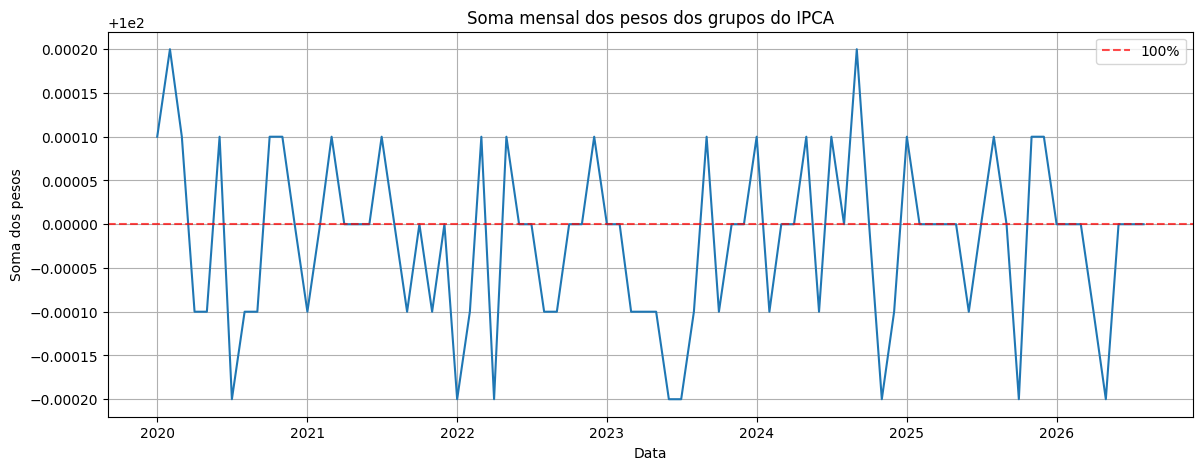

In [37]:
plt.figure(figsize=(14, 5))

plt.plot(
    pesos_grupos["date"],
    pesos_grupos["soma_pesos"],
)

plt.axhline(
    100,
    color="red",
    linestyle="--",
    alpha=0.7,
    label="100%",
)

plt.title("Soma mensal dos pesos dos grupos do IPCA")
plt.xlabel("Data")
plt.ylabel("Soma dos pesos")
plt.legend()
plt.grid(True)

plt.show()

### 22. Número de categorias ao longo do tempo

Mudanças metodológicas do IPCA podem produzir alterações no número de
categorias.

Isso não deve necessariamente gerar falha, mas precisa ser conhecido
antes da construção de features.

In [38]:
categorias_tempo = {}

for tabela in TABELAS_COMPONENTES:
    df_tmp = pd.read_sql(
        f"""
        SELECT
            date,
            COUNT(DISTINCT categoria) AS categorias
        FROM {SCHEMA}.{tabela}
        GROUP BY date
        ORDER BY date;
        """,
        engine,
    )

    categorias_tempo[tabela] = df_tmp

    print(f"\n{tabela}")
    display(
        df_tmp["categorias"].describe()
    )


ipca_grupos


count   80.0000
mean     9.0000
std      0.0000
min      9.0000
25%      9.0000
50%      9.0000
75%      9.0000
max      9.0000
Name: categorias, dtype: float64


ipca_subgrupos


count   80.0000
mean    19.0000
std      0.0000
min     19.0000
25%     19.0000
50%     19.0000
75%     19.0000
max     19.0000
Name: categorias, dtype: float64


ipca_itens


count   80.0000
mean    51.0000
std      0.0000
min     51.0000
25%     51.0000
50%     51.0000
75%     51.0000
max     51.0000
Name: categorias, dtype: float64


ipca_subitens


count    80.0000
mean    377.0000
std       0.0000
min     377.0000
25%     377.0000
50%     377.0000
75%     377.0000
max     377.0000
Name: categorias, dtype: float64

### 23. Contribuição aproximada dos grupos

Uma aproximação simples da contribuição de cada grupo é:

$$contribuição_{i,t}=indice_{i,t}
\times
\frac{peso_{i,t}}{100}
$$

Somando os grupos:

$$
\widehat{IPCA}_t =
\sum_i contribuição_{i,t}
$$

Esta comparação é diagnóstica.

Diferenças pequenas podem ocorrer por arredondamento ou metodologia.

In [39]:
contrib_grupos = pd.read_sql(
    """
    SELECT
        date,
        SUM(indice * peso / 100.0) AS ipca_componentes
    FROM bcb.ipca_grupos
    GROUP BY date
    ORDER BY date;
    """,
    engine,
)

contrib_grupos["date"] = pd.to_datetime(contrib_grupos["date"])
comparacao_ipca = (
    ipca[["date", "indice"]]
    .merge(
        contrib_grupos,
        on="date",
        how="inner",
    )
    .rename(
        columns={"indice": "ipca_geral"}
    )
)

comparacao_ipca["erro"] = (
    comparacao_ipca["ipca_componentes"]
    - comparacao_ipca["ipca_geral"]
)

comparacao_ipca["erro_abs"] = (
    comparacao_ipca["erro"].abs()
)

comparacao_ipca.tail(12)

,date,ipca_geral,ipca_componentes,erro,erro_abs
68,2025-09-01,0.4800,0.4829,0.0029,0.0029
69,2025-10-01,0.0900,0.0876,-0.0024,0.0024
70,2025-11-01,0.1800,0.1756,-0.0044,0.0044
71,2025-12-01,0.3300,0.3299,-0.0001,0.0001
72,2026-01-01,0.3300,0.3261,-0.0039,0.0039
73,2026-02-01,0.7000,0.7011,0.0011,0.0011
74,2026-03-01,0.8800,0.8748,-0.0052,0.0052
75,2026-04-01,0.6700,0.6654,-0.0046,0.0046
76,2026-05-01,0.5800,0.5852,0.0052,0.0052
77,2026-06-01,0.1600,0.1588,-0.0012,0.0012


In [40]:
comparacao_ipca["erro"].describe()

count   80.0000
mean    -0.0004
std      0.0033
min     -0.0065
25%     -0.0035
50%     -0.0008
75%      0.0024
max      0.0066
Name: erro, dtype: float64

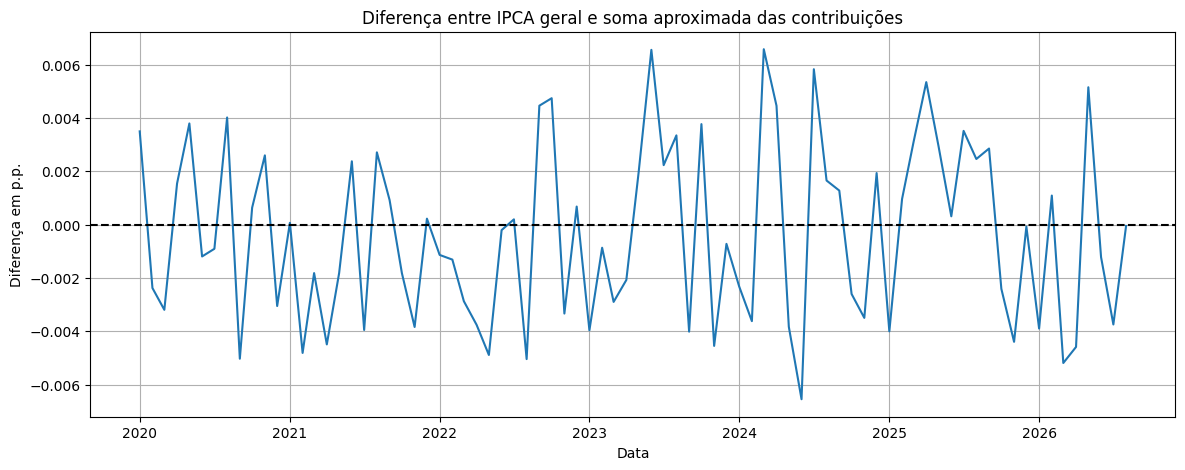

In [41]:
plt.figure(figsize=(14, 5))

plt.plot(
    comparacao_ipca["date"],
    comparacao_ipca["erro"],
)

plt.axhline(
    0,
    color="black",
    linestyle="--",
)

plt.title(
    "Diferença entre IPCA geral e soma aproximada das contribuições"
)

plt.xlabel("Data")
plt.ylabel("Diferença em p.p.")
plt.grid(True)

plt.show()

Neste primeiro momento não usamos `assert`.

Queremos primeiro conhecer empiricamente o erro produzido pela
decomposição para então estabelecer uma tolerância fundamentada.

---

## PARTE VII — SELIC



### 24. Carregar séries

In [42]:
selic_meta = pd.read_sql(
    """
    SELECT *
    FROM bcb.selic_meta
    ORDER BY date;
    """,
    engine,
)

selic_over = pd.read_sql(
    """
    SELECT *
    FROM bcb.selic_over
    ORDER BY date;
    """,
    engine,
)

selic_meta["date"] = pd.to_datetime(
    selic_meta["date"]
)

selic_over["date"] = pd.to_datetime(
    selic_over["date"]
)

### 25. SELIC Meta

In [43]:
selic_meta.tail(5)

,date,value,series_id,created_at,updated_at
9800,2026-10-31,13.7500,432,2026-09-27 13:01:26.852342,2026-09-27 13:01:26.852342
9801,2026-11-01,13.7500,432,2026-09-27 13:01:26.852342,2026-09-27 13:01:26.852342
9802,2026-11-02,13.7500,432,2026-09-27 13:01:26.852342,2026-09-27 13:01:26.852342
9803,2026-11-03,13.7500,432,2026-09-27 13:01:26.852342,2026-09-27 13:01:26.852342
9804,2026-11-04,13.7500,432,2026-09-27 13:01:26.852342,2026-09-27 13:01:26.852342


In [44]:
selic_meta["value"].describe()

count   9805.0000
mean      12.4431
std        4.8342
min        2.0000
25%        9.2500
50%       12.2500
75%       15.0000
max       26.5000
Name: value, dtype: float64

### 26. SELIC Over

In [45]:
selic_over.tail(5)

,date,value,series_id,created_at,updated_at
6710,2026-09-21,0.0508,11,2026-09-27 13:02:51.732589,2026-09-27 13:02:51.732589
6711,2026-09-22,0.0508,11,2026-09-27 13:02:51.732589,2026-09-27 13:02:51.732589
6712,2026-09-23,0.0508,11,2026-09-27 13:02:51.732589,2026-09-27 13:02:51.732589
6713,2026-09-24,0.0508,11,2026-09-27 13:02:51.732589,2026-09-27 13:02:51.732589
6714,2026-09-25,0.0508,11,2026-09-27 13:02:51.732589,2026-09-27 13:02:51.732589


In [46]:
selic_over["value"].describe()

count   6715.0000
mean       0.0459
std        0.0171
min        0.0075
25%        0.0347
50%        0.0456
75%        0.0551
max        0.0929
Name: value, dtype: float64

### 27. Sanity checks da SELIC

Os intervalos abaixo são deliberadamente amplos.

O objetivo não é definir limites econômicos formais, mas detectar
problemas evidentes de unidade ou parsing.

In [47]:
META_MIN = 0
META_MAX = 100

OVER_MIN = -10
OVER_MAX = 100

In [48]:
meta_invalidos = selic_meta.loc[
    ~selic_meta["value"].between(
        META_MIN,
        META_MAX,
    )
]

over_invalidos = selic_over.loc[
    ~selic_over["value"].between(
        OVER_MIN,
        OVER_MAX,
    )
]

print(
    "SELIC Meta fora da faixa:",
    len(meta_invalidos),
)

print(
    "SELIC Over fora da faixa:",
    len(over_invalidos),
)

SELIC Meta fora da faixa: 0
SELIC Over fora da faixa: 0


In [49]:
meta_ok = meta_invalidos.empty
over_ok = over_invalidos.empty

registrar_check(
    "SELIC",
    "Plausibilidade SELIC Meta",
    meta_ok,
    f"{len(meta_invalidos)} observações fora da faixa",
)

registrar_check(
    "SELIC",
    "Plausibilidade SELIC Over",
    over_ok,
    f"{len(over_invalidos)} observações fora da faixa",
)

assert meta_ok, (
    "SELIC Meta contém valores fora "
    "da faixa de sanity check."
)

assert over_ok, (
    "SELIC Over contém valores fora "
    "da faixa de sanity check."
)

In [71]:
nindice_invalido = ipca.loc[
    ipca["nindice"].notna()
    & (
        (ipca["nindice"] <= 0)
        | (ipca["nindice"] > 100_000)
    ),
    ["date", "nindice"],
]

ok = nindice_invalido.empty

registrar_check(
    "IPCA",
    "Plausibilidade do número-índice",
    ok,
    (
        f"{len(nindice_invalido)} observações "
        "fora da faixa de referência"
    ),
)

if not ok:
    display(nindice_invalido)

### 28. Densidade temporal da SELIC

Ao contrário do IPCA, não esperamos observações em todos os dias
corridos.

Portanto não fazemos um `date_range` diário e exigimos continuidade.

Avaliamos apenas a distribuição temporal observada.

In [50]:
intervalos_over = (
    selic_over["date"]
    .sort_values()
    .diff()
    .dt.days
)

intervalos_over.describe()

count   6714.0000
mean       1.4540
std        0.8694
min        1.0000
25%        1.0000
50%        1.0000
75%        1.0000
max        5.0000
Name: date, dtype: float64

In [51]:
intervalos_meta = (
    selic_meta["date"]
    .sort_values()
    .diff()
    .dt.days
)

intervalos_meta.describe()

count   9804.0000
mean       1.0000
std        0.0000
min        1.0000
25%        1.0000
50%        1.0000
75%        1.0000
max        1.0000
Name: date, dtype: float64

---

## PARTE VIII — VIEWS



### 29. Validar conteúdo das views

In [52]:
views_summary = []

for view in sorted(VIEWS_ESPERADAS):
    with engine.connect() as conn:
        quantidade = conn.execute(
            text(
                f"""
                SELECT COUNT(*)
                FROM {SCHEMA}.{view};
                """
            )
        ).scalar_one()

    views_summary.append(
        {
            "view": view,
            "registros": quantidade,
        }
    )

df_views = pd.DataFrame(views_summary)

df_views

,view,registros
0,vw_blocos_macro,377
1,vw_ipca_grupos_por_subitens,30160


In [53]:
for _, row in df_views.iterrows():
    ok = row["registros"] > 0

    registrar_check(
        "Views",
        row["view"],
        ok,
        f"{row['registros']:,} registros",
    )

    assert ok, (
        f"View {row['view']} não retornou dados."
    )

### 30. Amostra da view hierárquica

In [54]:
pd.read_sql(
    """
    SELECT *
    FROM bcb.vw_ipca_grupos_por_subitens
    ORDER BY date DESC
    LIMIT 5;
    """,
    engine,
)

,date,ipca_nindice,ipca_mensal,ipca_grupos,ipca_subgrupos,ipca_itens,ipca_subitens,ipca_grupos_contribuicao,ipca_subgrupos_contribuicao,ipca_itens_contribuicao,ipca_subitens_contribuicao,grupo_id,subgrupo_id,item_id,subitem_id,grupo_nome,subgrupo_nome,item_nome,subitem_nome
0,2026-08-01,7633.2300,-0.3200,-0.3400,-0.6100,-0.1100,1.3400,-0.0731,-0.0941,-0.0008,0.0067,1,11,1101,1101002,Alimentação e bebidas,Alimentação no domicílio,"Cereais, leguminosas e oleaginosas",Arroz
1,2026-08-01,7633.2300,-0.3200,-0.0900,-0.0900,-0.0900,0.0000,-0.0041,-0.0041,-0.0041,0.0000,9,91,9101,9101116,Comunicação,Comunicação,Comunicação,"Combo de telefonia, internet e tv por assinatura"
2,2026-08-01,7633.2300,-0.3200,-0.0900,-0.0900,-0.0900,0.0000,-0.0041,-0.0041,-0.0041,0.0000,9,91,9101,9101115,Comunicação,Comunicação,Comunicação,Serviços de streaming
3,2026-08-01,7633.2300,-0.3200,-0.0900,-0.0900,-0.0900,-0.6000,-0.0041,-0.0041,-0.0041,-0.0041,9,91,9101,9101019,Comunicação,Comunicação,Comunicação,Aparelho telefônico
4,2026-08-01,7633.2300,-0.3200,-0.0900,-0.0900,-0.0900,0.0000,-0.0041,-0.0041,-0.0041,0.0000,9,91,9101,9101018,Comunicação,Comunicação,Comunicação,Acesso à internet


### 31. Amostra dos blocos macro

In [55]:
pd.read_sql(
    """
    SELECT *
    FROM bcb.vw_blocos_macro
    LIMIT 10;
    """,
    engine,
)

,grupo_id,grupo_nome,subgrupo_id,subgrupo_nome,item_id,item_nome,subitem_id,subitem_nome
0,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101002,Arroz
1,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101051,Feijão - mulatinho
2,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101052,Feijão - preto
3,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101053,Feijão - macáçar (fradinho)
4,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101073,Feijão - carioca (rajado)
5,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101079,Milho (em grão)
6,1,Alimentação e bebidas,11,Alimentação no domicílio,1102,"Farinhas, féculas e massas",1102001,Farinha de arroz
7,1,Alimentação e bebidas,11,Alimentação no domicílio,1102,"Farinhas, féculas e massas",1102006,Macarrão
8,1,Alimentação e bebidas,11,Alimentação no domicílio,1102,"Farinhas, féculas e massas",1102008,Fubá de milho
9,1,Alimentação e bebidas,11,Alimentação no domicílio,1102,"Farinhas, féculas e massas",1102010,Flocos de milho


---

## PARTE IX — VISÃO CONSOLIDADA



### 32. Cobertura temporal

In [56]:
df_cobertura.sort_values(
    "tabela"
).reset_index(drop=True)

,tabela,registros,inicio,fim
0,ipca_geral,561,1979-12-01,2026-08-01
1,ipca_grupos,720,2020-01-01,2026-08-01
2,ipca_itens,4080,2020-01-01,2026-08-01
3,ipca_subgrupos,1520,2020-01-01,2026-08-01
4,ipca_subitens,30160,2020-01-01,2026-08-01
5,selic_meta,9805,2000-01-01,2026-11-04
6,selic_over,6715,2000-01-03,2026-09-25


### 33. Nulos encontrados

In [57]:
df_nulls_problematicos = (
    df_nulls[df_nulls["nulls"] > 0]
    .sort_values(
        ["tabela", "percentual"],
        ascending=[True, False],
    )
    .reset_index(drop=True)
)

df_nulls_problematicos

,tabela,coluna,nulls,percentual
0,ipca_geral,acumulado12m,12,2.1390
1,ipca_geral,indice,1,0.1783
2,ipca_geral,acumulado,1,0.1783
3,ipca_grupos,acumulado,99,13.7500
4,ipca_itens,acumulado,561,13.7500
5,ipca_subgrupos,acumulado,209,13.7500
6,ipca_subitens,acumulado,4147,13.7500


### 34. Resultado das validações

In [58]:
df_resultados = pd.DataFrame(resultados)

df_resultados

,categoria,teste,status,detalhe
0,PostgreSQL,Conexão com o banco,OK,database=bcb | usuario=moacir
1,PostgreSQL,Schema bcb,OK,
2,PostgreSQL,Tabelas esperadas,OK,Todas encontradas
3,PostgreSQL,Views esperadas,OK,Todas encontradas
4,Schema,ipca_geral,OK,Contrato OK
5,Schema,ipca_grupos,OK,Contrato OK
6,Schema,ipca_subgrupos,OK,Contrato OK
7,Schema,ipca_itens,OK,Contrato OK
8,Schema,ipca_subitens,OK,Contrato OK
9,Schema,selic_meta,OK,Contrato OK


In [59]:
resumo_status = (
    df_resultados
    .groupby(["categoria", "status"])
    .size()
    .unstack(fill_value=0)
)

resumo_status

status,AVISO,OK
categoria,,
Cobertura,0,7
Duplicidades,0,7
Hierarquia IPCA,0,4
IPCA,1,1
Nulls críticos,1,6
PostgreSQL,0,4
SELIC,0,2
Schema,0,7
Views,0,2


### 35. Falhas encontradas

In [60]:
falhas = df_resultados[
    df_resultados["status"] == "FALHA"
].copy()

avisos = df_resultados[
    df_resultados["status"] == "AVISO"
].copy()

auditoria_ok = falhas.empty

In [61]:
print("OK:", (df_resultados["status"] == "OK").sum())
print("AVISOS:", len(avisos))
print("FALHAS:", len(falhas))


OK: 40
AVISOS: 2
FALHAS: 0


In [62]:
avisos[
    ["categoria", "teste", "detalhe"]
].reset_index(drop=True)

,categoria,teste,detalhe
0,Nulls críticos,ipca_geral,1 valores nulos
1,IPCA,Plausibilidade da variação mensal,5 observações fora da faixa


In [63]:
assert auditoria_ok, (
    "Auditoria reprovada. "
    "Existem validações com status FALHA."
)

### 36. Status final da auditoria

In [64]:
auditoria_ok = falhas.empty

print("=" * 60)
print("AUDITORIA PÓS-ATUALIZAÇÃO")
print("=" * 60)

print(
    f"PostgreSQL : "
    f"{'OK' if not df_resultados.query(
        'categoria == \"PostgreSQL\" and status == \"FALHA\"'
    ).shape[0] else 'FALHA'}"
)

print(
    f"Schema     : "
    f"{'OK' if not df_resultados.query(
        'categoria == \"Schema\" and status == \"FALHA\"'
    ).shape[0] else 'FALHA'}"
)

print(
    f"IPCA       : "
    f"{'OK' if not df_resultados[
        (df_resultados['categoria'].isin(
            ['IPCA', 'Hierarquia IPCA']
        ))
        & (df_resultados['status'] == 'FALHA')
    ].shape[0] else 'FALHA'}"
)

print(
    f"SELIC      : "
    f"{'OK' if not df_resultados.query(
        'categoria == \"SELIC\" and status == \"FALHA\"'
    ).shape[0] else 'FALHA'}"
)

print(
    f"Views      : "
    f"{'OK' if not df_resultados.query(
        'categoria == \"Views\" and status == \"FALHA\"'
    ).shape[0] else 'FALHA'}"
)

print("-" * 60)

if auditoria_ok:
    print("STATUS FINAL: APROVADO PARA ANÁLISE")
else:
    print("STATUS FINAL: REPROVADO")
    print("Corrija as falhas antes de prosseguir.")

print("=" * 60)

AUDITORIA PÓS-ATUALIZAÇÃO
PostgreSQL : OK
Schema     : OK
IPCA       : OK
SELIC      : OK
Views      : OK
------------------------------------------------------------
STATUS FINAL: APROVADO PARA ANÁLISE


In [65]:
assert auditoria_ok, (
    "Auditoria reprovada. "
    "Existem validações com status FALHA."
)

- Falhas

In [66]:
falhas[
    ["categoria", "teste", "detalhe"]
].reset_index(drop=True)

,categoria,teste,detalhe


---

### 37. Resumo das séries disponíveis para análise

In [67]:
print("IPCA")
print("-" * 50)

print(
    "Início:",
    ipca["date"].min().date(),
)

print(
    "Fim:",
    ipca["date"].max().date(),
)

print(
    "Observações:",
    len(ipca),
)

IPCA
--------------------------------------------------
Início: 1979-12-01
Fim: 2026-08-01
Observações: 561


In [68]:
print("SELIC META")
print("-" * 50)

print(
    "Início:",
    selic_meta["date"].min().date(),
)

print(
    "Fim:",
    selic_meta["date"].max().date(),
)

print(
    "Observações:",
    len(selic_meta),
)

SELIC META
--------------------------------------------------
Início: 2000-01-01
Fim: 2026-11-04
Observações: 9805


In [69]:
print("SELIC OVER")
print("-" * 50)

print(
    "Início:",
    selic_over["date"].min().date(),
)

print(
    "Fim:",
    selic_over["date"].max().date(),
)

print(
    "Observações:",
    len(selic_over),
)

SELIC OVER
--------------------------------------------------
Início: 2000-01-03
Fim: 2026-09-25
Observações: 6715


In [70]:
ipca_fora_faixa[
    ["date", "indice"]
].sort_values("date")

,date,indice
0,1979-12-01,NaN
120,1989-12-01,51.5000
121,1990-01-01,67.5500
122,1990-02-01,75.7300
123,1990-03-01,82.3900


### 38. Conclusão

Este notebook representa o gate de qualidade entre a engenharia de dados
e a camada analítica do projeto.

O fluxo operacional esperado passa a ser:

```text
IBGE/SIDRA ──┐
             ├──> pipelines ──> PostgreSQL
BCB/SGS ─────┘                    │
                                  │
                                  v
                                views
                                  │
                                  v
                      00.auditoria_dados
                                  │
                      ┌───────────┴───────────┐
                      │                       │
                    FALHA                    OK
                      │                       │
                      v                       v
              corrigir pipeline       análises econômicas
                                              │
                                              v
                                      feature engineering
                                              │
                                              v
                                           modelos
```



### Critério operacional

Se este notebook falhar:

**não devemos prosseguir para os notebooks analíticos.**

A correção deve acontecer na origem do problema:

- API client;
- pipeline;
- migration;
- carga;
- view;
- configuração do banco.

O notebook não deve corrigir silenciosamente o dado.

---



### Próxima etapa

Com a auditoria aprovada, seguimos para:

```text
01._selic.ipynb
```

Nesse notebook deixamos de perguntar:

> "Os dados estão íntegros?"

e passamos a perguntar:

> "O que os dados da SELIC nos dizem economicamente?"

Essa separação será mantida nos demais notebooks e, principalmente,
na futura camada de modelagem.